The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


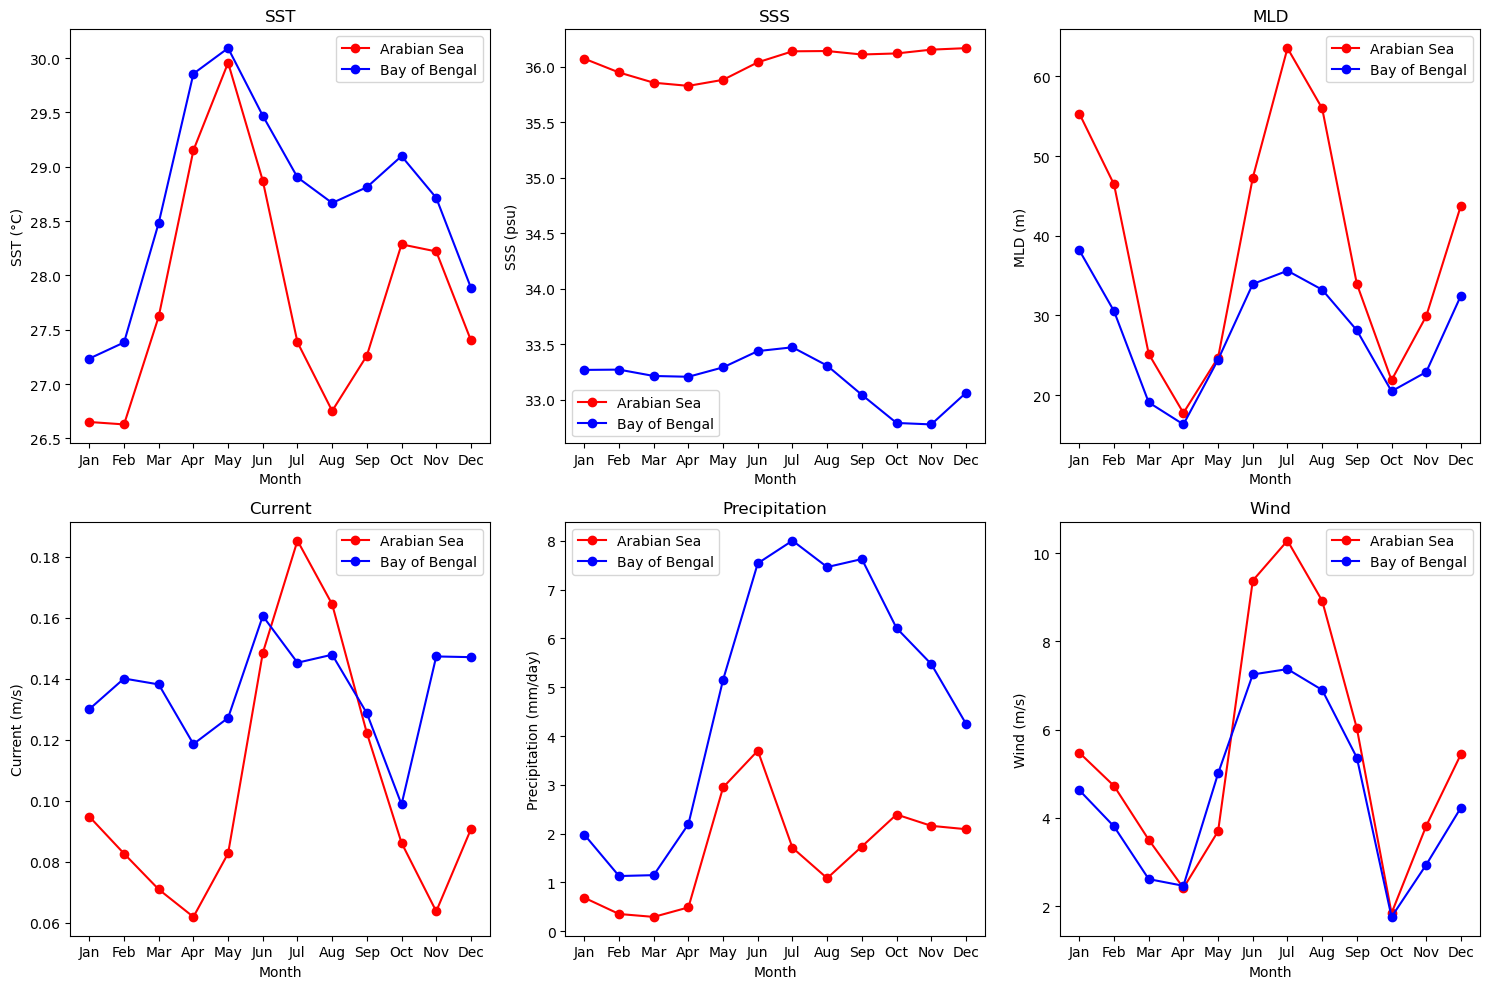

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import calendar

# Function to calculate climatology
def calculate_climatology(data, time_dim, lat_dim, lon_dim):
    data_climatology = data.groupby(f'{time_dim}.month').mean(dim=time_dim)
    data_mean = data_climatology.mean(dim=[lat_dim, lon_dim])
    return data_mean

# Read and process data in the desired order
data2 = xr.open_dataset('sst.nc')
ds2 = data2.sel(time_counter=slice('1993', '2021'), lat=slice(5, 20), lon=slice(55, 70))
climatology_b = calculate_climatology(ds2['sosstsst'], 'time_counter', 'lat', 'lon')

data5 = xr.open_dataset('mld2.nc')
data5 = data5.sel(lat=slice(5, 20), lon=slice(55, 70))
climatology_e = np.nanmean(data5['somxl030'], axis=(1, 2))

data9 = xr.open_dataset('salinity2.nc')
data9 = data9.sel(lat=slice(5, 20), lon=slice(55, 70))
climatology_i = np.nanmean(data9['sosaline'], axis=(1, 2))

data8 = xr.open_dataset('erawind.nc')
ds8 = data8.sel(TIME=slice('1993', '2021'), LAT241_481=slice(5, 20), LON161_481=slice(55, 70))
u_clim1 = ds8['U10'].groupby('TIME.month').mean(dim='TIME', skipna=True)
v_clim1 = ds8['V10'].groupby('TIME.month').mean(dim='TIME', skipna=True)
wind = np.sqrt(u_clim1**2 + v_clim1**2)
climatology_h = wind.mean(dim=['LAT241_481', 'LON161_481'])

data4 = xr.open_dataset('precipitation.nc')
ds4 = data4.sel(TIME=slice('1993', '2021'), LAT=slice(5, 20), LONN179_181=slice(55, 70))
climatology_d = calculate_climatology(ds4['PRECIP'], 'TIME', 'LAT', 'LONN179_181')

data7 = xr.open_dataset('current.nc')
ds7 = data7.sel(TIME=slice('1993', '2021'), LAT=slice(5, 20), LONN719_721=slice(55, 70))
u_clim = ds7['U'].groupby('TIME.month').mean(dim='TIME', skipna=True)
v_clim = ds7['V'].groupby('TIME.month').mean(dim='TIME', skipna=True)
current = np.sqrt(u_clim**2 + v_clim**2)
climatology_g = current.mean(dim=['LAT', 'LONN719_721'])

variables1 = [climatology_b, climatology_i, climatology_e, climatology_g, climatology_d, climatology_h]

data2_2 = xr.open_dataset('sst.nc')
ds2_2 = data2_2.sel(time_counter=slice('1993', '2021'), lat=slice(5, 20), lon=slice(80, 92))
climatology_b_2 = calculate_climatology(ds2_2['sosstsst'], 'time_counter', 'lat', 'lon')

data5_2 = xr.open_dataset('mld2.nc')
data5_2 = data5_2.sel(lat=slice(5, 20), lon=slice(80, 92))
climatology_e_2 = np.nanmean(data5_2['somxl030'], axis=(1, 2))

data9_2 = xr.open_dataset('salinity2.nc')
data9_2 = data9_2.sel(lat=slice(5, 20), lon=slice(80, 92))
climatology_i_2 = np.nanmean(data9_2['sosaline'], axis=(1, 2))

data8_2 = xr.open_dataset('erawind.nc')
ds8_2 = data8_2.sel(TIME=slice('1993', '2021'), LAT241_481=slice(5, 20), LON161_481=slice(80, 92))
u_clim1_2 = ds8_2['U10'].groupby('TIME.month').mean(dim='TIME', skipna=True)
v_clim1_2 = ds8_2['V10'].groupby('TIME.month').mean(dim='TIME', skipna=True)
wind_2 = np.sqrt(u_clim1_2**2 + v_clim1_2**2)
climatology_h_2 = wind_2.mean(dim=['LAT241_481', 'LON161_481'])

data4_2 = xr.open_dataset('precipitation.nc')
ds4_2 = data4_2.sel(TIME=slice('1993', '2021'), LAT=slice(5, 20), LONN179_181=slice(80, 92))
climatology_d_2 = calculate_climatology(ds4_2['PRECIP'], 'TIME', 'LAT', 'LONN179_181')

data7_2 = xr.open_dataset('current.nc')
ds7_2 = data7_2.sel(TIME=slice('1993', '2021'), LAT=slice(5, 20), LONN719_721=slice(80, 92))
u_clim_2 = ds7_2['U'].groupby('TIME.month').mean(dim='TIME', skipna=True)
v_clim_2 = ds7_2['V'].groupby('TIME.month').mean(dim='TIME', skipna=True)
#current_2 = np.sqrt(u_clim_2**2 + v_clim_2**2)
climatology_g_2 = current_2.mean(dim=['LAT', 'LONN719_721'])

variables2 = [climatology_b_2, climatology_i_2, climatology_e_2, climatology_g_2, climatology_d_2, climatology_h_2]

# Plotting
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

titles = ['SST', 'SSS', 'MLD', 'Current', 'Precipitation', 'Wind']
units = ['SST (°C)', 'SSS (psu)', 'MLD (m)', 'Current (m/s)', 'Precipitation (mm/day)', 'Wind (m/s)']
months = np.arange(1, 13)

for i, (var1, var2, title, unit) in enumerate(zip(variables1, variables2, titles, units)):
    ax = axs[i // 3, i % 3]
    ax.plot(months, var1, marker='o', color='red', label='Arabian Sea')
    ax.plot(months, var2, marker='o', color='blue', label='Bay of Bengal')
    ax.set_title(title)
    ax.set_xlabel('Month')
    ax.set_ylabel(unit)
    ax.set_xticks(months)
    ax.set_xticklabels([calendar.month_abbr[m] for m in months])
    ax.legend()

plt.tight_layout()
plt.savefig(r'C:\Users\henna\Desktop\plots\6plots.eps',format='eps',dpi=300)
plt.show()


In [7]:
from scipy.stats import pearsonr
import numpy as np

# Ensure all variables are numpy arrays for correlation calculation
variables1 = [var.values.flatten() if hasattr(var, 'values') else var.flatten() for var in variables1]
variables2 = [var.values.flatten() if hasattr(var, 'values') else var.flatten() for var in variables2]

# Define variable names for clarity
variable_names = ['SST','SSS','MLD','Current','Precipitation','Wind']

# Function to compute and print correlations
def compute_and_print_correlations(variables, variable_names, region_name):
    n = len(variables)
    for i in range(n):
        for j in range(i + 1, n):
            corr, _ = pearsonr(variables[i], variables[j])
            print(f'Correlation between {variable_names[i]} and {variable_names[j]} in {region_name}: {corr:.2f}')

# Compute correlations within Arabian Sea
print("Correlations within Arabian Sea:")
compute_and_print_correlations(variables1, variable_names, "Arabian Sea")

# Compute correlations within Bay of Bengal
print("\nCorrelations within Bay of Bengal:")
compute_and_print_correlations(variables2, variable_names, "Bay of Bengal")


Correlations within Arabian Sea:
Correlation between SST and SSS in Arabian Sea: -0.46
Correlation between SST and MLD in Arabian Sea: -0.64
Correlation between SST and Current in Arabian Sea: -0.29
Correlation between SST and Precipitation in Arabian Sea: 0.57
Correlation between SST and Wind in Arabian Sea: -0.34
Correlation between SSS and MLD in Arabian Sea: 0.53
Correlation between SSS and Current in Arabian Sea: 0.49
Correlation between SSS and Precipitation in Arabian Sea: 0.34
Correlation between SSS and Wind in Arabian Sea: 0.46
Correlation between MLD and Current in Arabian Sea: 0.76
Correlation between MLD and Precipitation in Arabian Sea: -0.04
Correlation between MLD and Wind in Arabian Sea: 0.86
Correlation between Current and Precipitation in Arabian Sea: 0.26
Correlation between Current and Wind in Arabian Sea: 0.93
Correlation between Precipitation and Wind in Arabian Sea: 0.23

Correlations within Bay of Bengal:
Correlation between SST and SSS in Bay of Bengal: 0.05
C

In [29]:
# Assuming variables1 and variables2 are your datasets
sst_arabian_sea = variables1[0]  # Assuming SST is the first variable
sst_bay_of_bengal = variables2[0]  # Assuming SST is the first variable

# Compute correlation directly
corr_sst_arabian_sea, _ = pearsonr(sst_arabian_sea, sst_arabian_sea)
corr_sst_bay_of_bengal, _ = pearsonr(sst_bay_of_bengal, sst_bay_of_bengal)

print(f"Correlation SST in Arabian Sea: {corr_sst_arabian_sea:.6f}")
print(f"Correlation SST in Bay of Bengal: {corr_sst_bay_of_bengal:.6f}")

Correlation SST in Arabian Sea: 1.000000
Correlation SST in Bay of Bengal: 1.000000


Correlations within Arabian Sea:


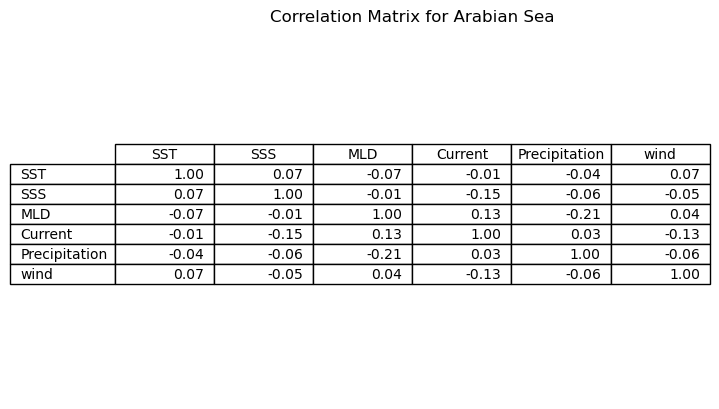


Correlations within Bay of Bengal:


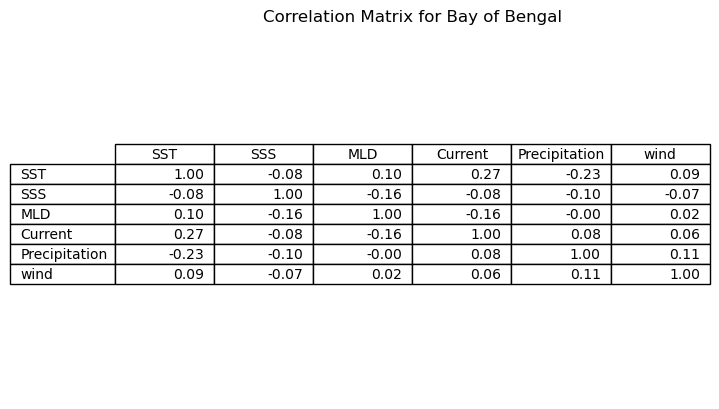

In [38]:
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Ensure all variables are numpy arrays for correlation calculation
variables1 = [var.values.flatten() if hasattr(var, 'values') else var.flatten() for var in variables1]
variables2 = [var.values.flatten() if hasattr(var, 'values') else var.flatten() for var in variables2]

# Define variable names for clarity
variable_names = ['SST','SSS','MLD', 'Current', 'Precipitation','wind']

# Function to compute correlations and return them in a matrix
def compute_correlations(variables):
    n = len(variables)
    corr_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            corr, _ = pearsonr(variables[i], variables[j])
            corr_matrix[i, j] = corr
            corr_matrix[j, i] = corr
    return corr_matrix

# Compute correlations for Arabian Sea and Bay of Bengal
corr_matrix_arabian = compute_correlations(variables1)
corr_matrix_bay = compute_correlations(variables2)

# Function to plot the correlation matrix as a table
def plot_correlation_table(corr_matrix, variable_names, region_name):
    fig, ax = plt.subplots()
    ax.axis('tight')
    ax.axis('off')
    table_data = [[f'{corr_matrix[i, j]:.2f}' for j in range(len(variable_names))] for i in range(len(variable_names))]
    table = ax.table(cellText=table_data, colLabels=variable_names, rowLabels=variable_names, loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)
    plt.title(f'Correlation Matrix for {region_name}')
    plt.show()

# Plot correlation tables for Arabian Sea and Bay of Bengal
print("Correlations within Arabian Sea:")
plot_correlation_table(corr_matrix_arabian, variable_names, "Arabian Sea")

print("\nCorrelations within Bay of Bengal:")
plot_correlation_table(corr_matrix_bay, variable_names, "Bay of Bengal")

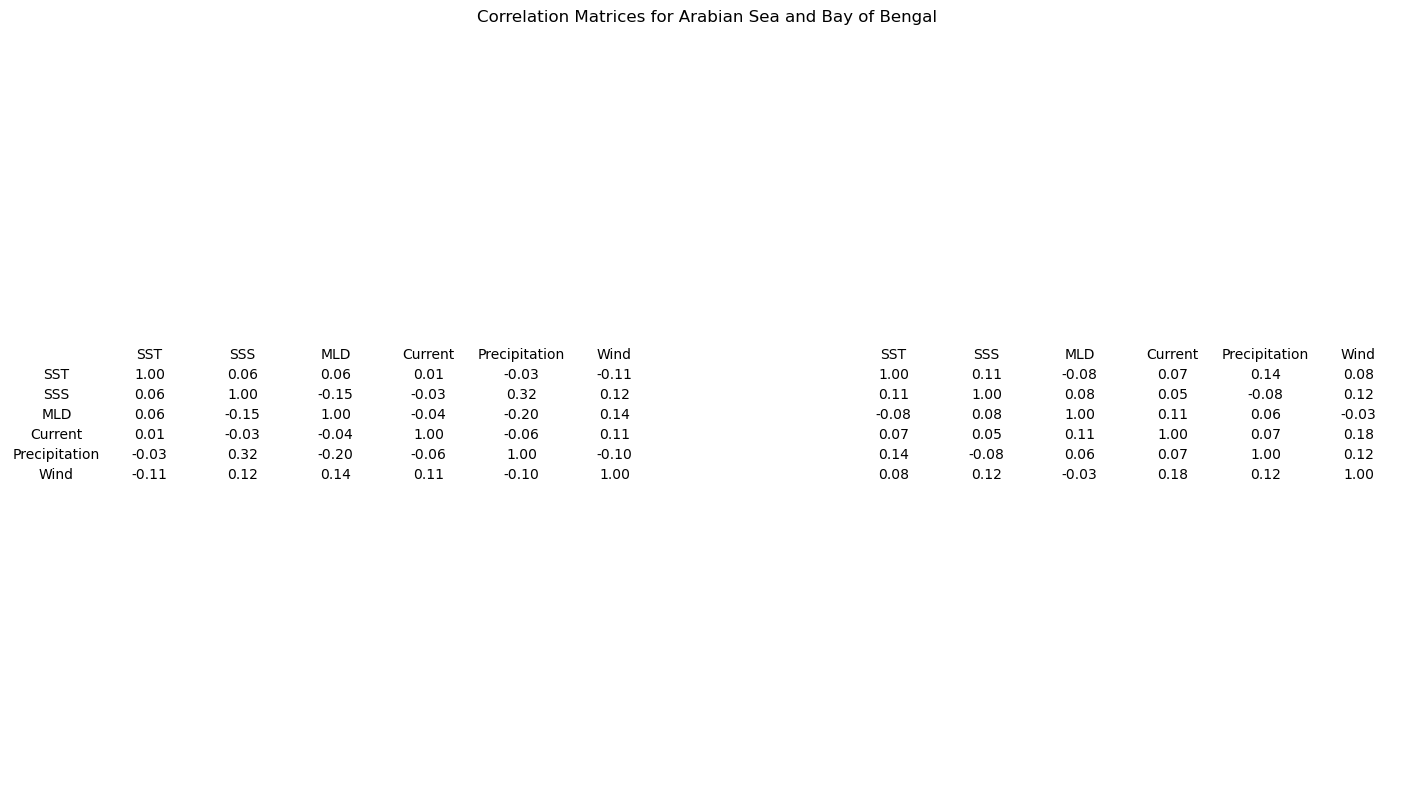

In [39]:
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Example data (replace with your actual data)
variables1 = [np.random.rand(100) for _ in range(8)]  # Example data for variables1
variables2 = [np.random.rand(100) for _ in range(8)]  # Example data for variables2

# Define variable names for clarity
variable_names = ['SST','SSS','MLD','Current', 'Precipitation','Wind']

# Ensure all variables are numpy arrays for correlation calculation
variables1 = [var.flatten() for var in variables1]
variables2 = [var.flatten() for var in variables2]

# Function to compute correlations and return them in a matrix
def compute_correlations(variables):
    n = len(variables)
    corr_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            corr, _ = pearsonr(variables[i], variables[j])
            corr_matrix[i, j] = corr
            corr_matrix[j, i] = corr
    return corr_matrix

# Compute correlations for Arabian Sea and Bay of Bengal
corr_matrix_arabian = compute_correlations(variables1)
corr_matrix_bay = compute_correlations(variables2)

# Function to combine two correlation matrices into a single table data
def combine_correlation_matrices(corr_matrix1, corr_matrix2, variable_names):
    n = len(variable_names)
    combined_table = [["" for _ in range(2*n+3)] for _ in range(n+1)]
    combined_table[0][0] = ""
    
    # Headers for Arabian Sea
    for i in range(n):
        combined_table[0][i+1] = variable_names[i]
        combined_table[i+1][0] = variable_names[i]

    # Headers for Bay of Bengal
    for i in range(n):
        combined_table[0][n+2+i+1] = variable_names[i]

    # Fill in the correlation values for Arabian Sea
    for i in range(n):
        for j in range(n):
            combined_table[i+1][j+1] = f'{corr_matrix1[i, j]:.2f}'

    # Fill in the correlation values for Bay of Bengal
    for i in range(n):
        for j in range(n):
            combined_table[i+1][n+2+j+1] = f'{corr_matrix2[i, j]:.2f}'
    
    return combined_table

# Combine the correlation matrices
combined_table_data = combine_correlation_matrices(corr_matrix_arabian, corr_matrix_bay, variable_names)

# Function to plot the combined correlation table
def plot_combined_correlation_table(combined_table_data, region_name1, region_name2):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.axis('tight')
    ax.axis('off')
    table = ax.table(cellText=combined_table_data, cellLoc='center', loc='center', edges='open')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)
    plt.title(f'Correlation Matrices for {region_name1} and {region_name2}')
    plt.show()

# Plot the combined correlation table for Arabian Sea and Bay of Bengal
plot_combined_correlation_table(combined_table_data, "Arabian Sea", "Bay of Bengal")

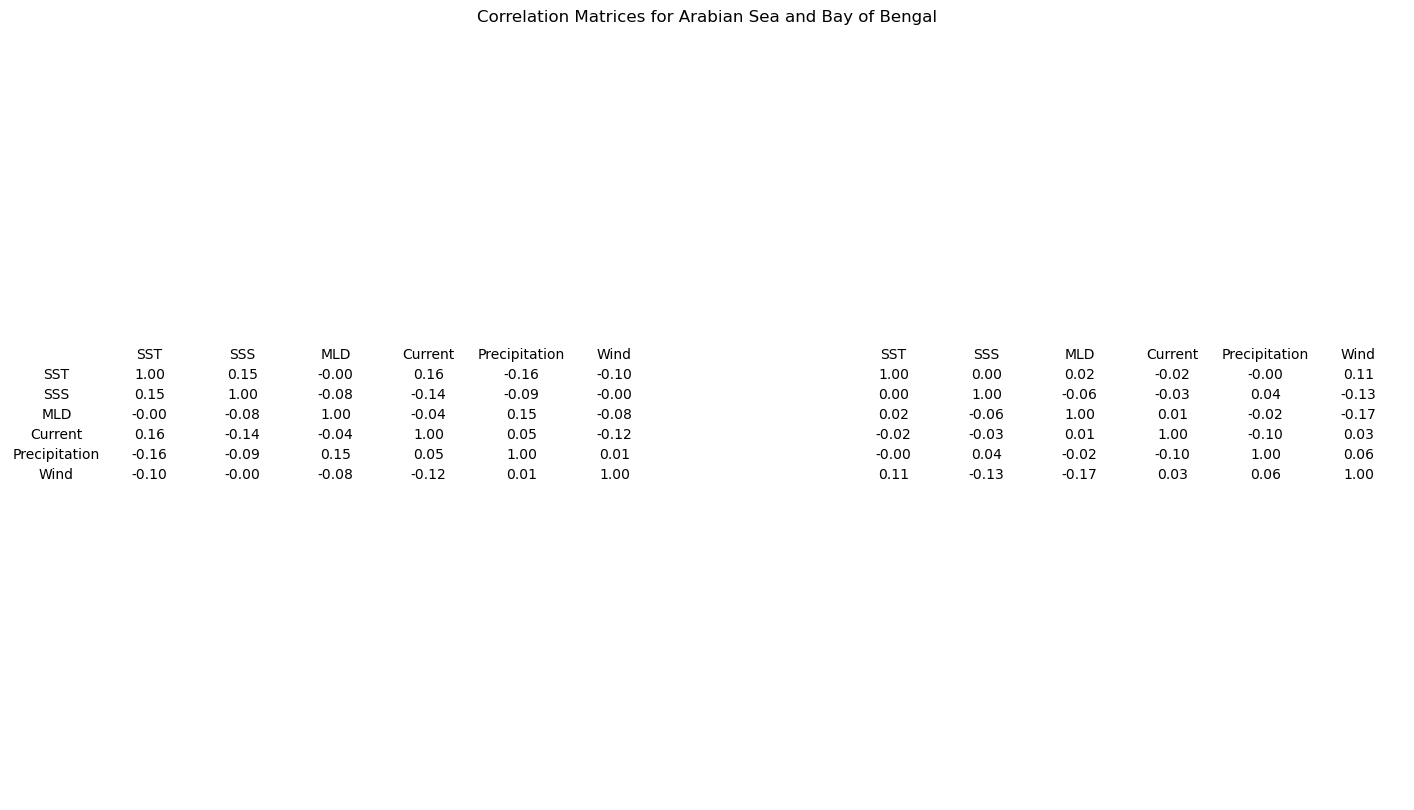

In [40]:
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Example data (replace with your actual data)
variables1 = [np.random.rand(100) for _ in range(8)]  # Example data for variables1
variables2 = [np.random.rand(100) for _ in range(8)]  # Example data for variables2

# Define variable names for clarity
variable_names = ['SST','SSS','MLD','Current','Precipitation','Wind']

# Ensure all variables are numpy arrays for correlation calculation
variables1 = [var.flatten() for var in variables1]
variables2 = [var.flatten() for var in variables2]

# Compute correlation matrices using numpy.corrcoef
corr_matrix_arabian = np.corrcoef(variables1)
corr_matrix_bay = np.corrcoef(variables2)

# Function to combine two correlation matrices into a single table data
def combine_correlation_matrices(corr_matrix1, corr_matrix2, variable_names):
    n = len(variable_names)
    combined_table = [["" for _ in range(2*n+3)] for _ in range(n+1)]
    combined_table[0][0] = ""
    
    # Headers for Arabian Sea
    for i in range(n):
        combined_table[0][i+1] = variable_names[i]
        combined_table[i+1][0] = variable_names[i]

    # Headers for Bay of Bengal
    for i in range(n):
        combined_table[0][n+2+i+1] = variable_names[i]

    # Fill in the correlation values for Arabian Sea
    for i in range(n):
        for j in range(n):
            combined_table[i+1][j+1] = f'{corr_matrix1[i, j]:.2f}'

    # Fill in the correlation values for Bay of Bengal
    for i in range(n):
        for j in range(n):
            combined_table[i+1][n+2+j+1] = f'{corr_matrix2[i, j]:.2f}'
    
    return combined_table

# Combine the correlation matrices
combined_table_data = combine_correlation_matrices(corr_matrix_arabian, corr_matrix_bay, variable_names)

# Function to plot the combined correlation table
def plot_combined_correlation_table(combined_table_data, region_name1, region_name2):
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.axis('tight')
    ax.axis('off')
    table = ax.table(cellText=combined_table_data, cellLoc='center', loc='center', edges='open')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.2)
    plt.title(f'Correlation Matrices for {region_name1} and {region_name2}')
    plt.show()

# Plot the combined correlation table for Arabian Sea and Bay of Bengal
plot_combined_correlation_table(combined_table_data, "Arabian Sea", "Bay of Bengal")


In [104]:
import numpy as np
ss=np.corrcoef(climatology_h_2,climatology_h_2)
print(ss)

[[1. 1.]
 [1. 1.]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import calendardata7_2 = xr.open_dataset('current.nc')
ds7_2 = data7_2.sel(TIME=slice('1993', '2021'), LAT=slice(5, 20), LONN719_721=slice(80, 92))
u_clim_2 = ds7_2['U'].groupby('TIME.month').mean(dim='TIME', skipna=True)
v_clim_2 = ds7_2['V'].groupby('TIME.month').mean(dim='TIME', skipna=True)
#current_2 = np.sqrt(u_clim_2**2 + v_clim_2**2)
climatology_g_2 = u_clim_2.mean(dim=['LAT', 'LONN719_721'])
climatology_g_3=v_clim_2.mean(dim=['LAT', 'LONN719_721'])
for i, (var1, var2, title, unit) in enumerate(zip(variables1, variables2, titles, units)):
    ax = axs[i // 3, i % 3]
    ax.plot(months, var1, marker='o', color='red', label='Arabian Sea')
    ax.plot(months, var2, marker='o', color='blue', label='Bay of Bengal')
    ax.set_title(title)
    ax.set_xlabel('Month')
    ax.set_ylabel(unit)
    ax.set_xticks(months)
    ax.set_xticklabels([calendar.month_abbr[m] for m in months])
    ax.legend()

plt.tight_layout()
plt.show()
